# Mango Leaf Disease Classification with a Basic CNN (PyTorch)

**Course:** Computer Vision and Pattern Recognition
**Dataset:** MangoLeafBD (Mendeley Data, DOI: 10.17632/hxsnvwty3r.1), also published in *Data in Brief*, Vol. 47, 2023

**Dataset facts**
- 4,000 JPG images of mango leaves, size 240 x 320
- 8 classes, 500 images each (balanced): Anthracnose, Bacterial Canker, Cutting Weevil, Die Back, Gall Midge, Healthy, Powdery Mildew, Sooty Mould
- Collected from 4 mango orchards in Bangladesh using a mobile phone camera
- Small download size, well under the 2.5 GB limit

**Goal:** build a basic CNN from scratch that looks at a leaf photo and predicts which of the 8 classes it belongs to.

## 1. Setup

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt
import numpy as np
import os

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(device)

# make results repeatable
torch.manual_seed(42)
np.random.seed(42)

cuda


## 2. Get the dataset

**Easiest way:** open https://data.mendeley.com/datasets/hxsnvwty3r/1, click **Download All**, then upload the zip file to Colab (left sidebar, Files, Upload) or to your Google Drive.

The cell below:
1. Looks for the dataset folder if it is already on disk.
2. If not found, unzips any `.zip` you uploaded (Colab folder or `MyDrive`).
3. If still nothing, tries to download it straight from Mendeley.

In [ ]:
import zipfile, glob, subprocess

CLASS_HINT = "Healthy"   # one of the class folder names

def find_data_dir(root):
    # returns the folder that directly contains the class folders
    for current, subdirs, _ in os.walk(root):
        if CLASS_HINT in subdirs:
            return current
    return None

def search():
    for root in [".", "/content", "/content/drive/MyDrive"]:
        if os.path.exists(root):
            d = find_data_dir(root)
            if d:
                return d
    return None

data_dir = search()

# Option A: unzip an uploaded zip (Colab or Google Drive)
if data_dir is None:
    try:
        from google.colab import drive
        drive.mount('/content/drive')
    except Exception:
        pass
    zips = glob.glob("*.zip") + glob.glob("/content/*.zip") + glob.glob("/content/drive/MyDrive/*.zip")
    for z in zips:
        if "mango" in z.lower() or "hxsnvwty3r" in z.lower():
            print("Unzipping", z)
            zipfile.ZipFile(z).extractall("mango_data")
    # the Mendeley zip sometimes has another zip inside it
    for z in glob.glob("mango_data/**/*.zip", recursive=True):
        zipfile.ZipFile(z).extractall(os.path.dirname(z))
    data_dir = search()

# Option B: direct download from Mendeley
if data_dir is None:
    url = "https://data.mendeley.com/public-api/zip/hxsnvwty3r/download/1"
    subprocess.run(["wget", "-q", "-O", "mango.zip", url])
    if os.path.exists("mango.zip") and zipfile.is_zipfile("mango.zip"):
        zipfile.ZipFile("mango.zip").extractall("mango_data")
        for z in glob.glob("mango_data/**/*.zip", recursive=True):
            zipfile.ZipFile(z).extractall(os.path.dirname(z))
        data_dir = search()

assert data_dir is not None, "Dataset not found. Download the zip from Mendeley and upload it, then run this cell again."
print("Dataset folder:", data_dir)
print("Classes:", sorted(os.listdir(data_dir)))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Unzipping MangoLeafBD Dataset.zip
Unzipping /content/MangoLeafBD Dataset.zip
Unzipping /content/drive/MyDrive/MangoLeafBD Dataset.zip
Dataset folder: ./mango_data/MangoLeafBD Dataset
Classes: ['Anthracnose', 'Bacterial Canker', 'Cutting Weevil', 'Die Back', 'Gall Midge', 'Healthy', 'Powdery Mildew', 'Sooty Mould']


## 3. Transforms and train/test split

The dataset comes as one folder per class, with **no ready-made train/test split**. So we split it ourselves:
- **80% training** (the model learns from these)
- **20% testing / validation** (the model never trains on these, we only use them to check performance)

**Transforms**
- All images are resized to **128 x 128** so they have the same size.
- The **training** set also gets light augmentation (flip, small rotation, brightness/contrast change). This gives the model more variety and reduces overfitting.
- The **test** set gets only resize + ToTensor, because we want to test on normal images.

In [ ]:
IMG_SIZE = 128

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),          # flip left-right
    transforms.RandomRotation(15),              # rotate +-15 degrees
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor()                       # PIL -> tensor in [0,1]
])

val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
])

# Two views of the same folder: one with augmentation, one without
full_train = datasets.ImageFolder(data_dir, transform=train_transform)
full_val   = datasets.ImageFolder(data_dir, transform=val_transform)
class_names = full_train.classes
num_classes = len(class_names)

# 80 / 20 split with a fixed seed
n = len(full_train)
idx = torch.randperm(n, generator=torch.Generator().manual_seed(42)).tolist()
split = int(0.8 * n)
train_data = Subset(full_train, idx[:split])
test_data  = Subset(full_val,   idx[split:])

print("Classes:", class_names)
print("Total images:", n)
print(f"Trn: {len(train_data)}")
print(f"Tst: {len(test_data)}")

Classes: ['Anthracnose', 'Bacterial Canker', 'Cutting Weevil', 'Die Back', 'Gall Midge', 'Healthy', 'Powdery Mildew', 'Sooty Mould']
Total images: 4000
Trn: 3200
Tst: 800


### Images per class (checking the dataset is balanced)

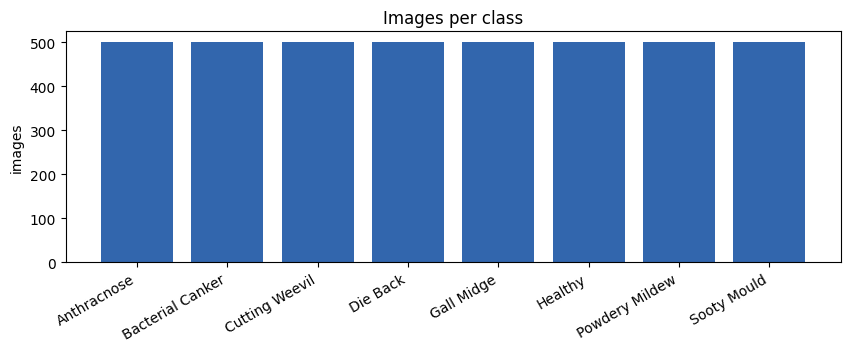

In [ ]:
counts = np.bincount([label for _, label in full_train.samples], minlength=num_classes)
plt.figure(figsize=(10,3))
plt.bar(class_names, counts, color="#3266ad")
plt.xticks(rotation=30, ha="right")
plt.ylabel("images")
plt.title("Images per class")
plt.show()

### Look at some images

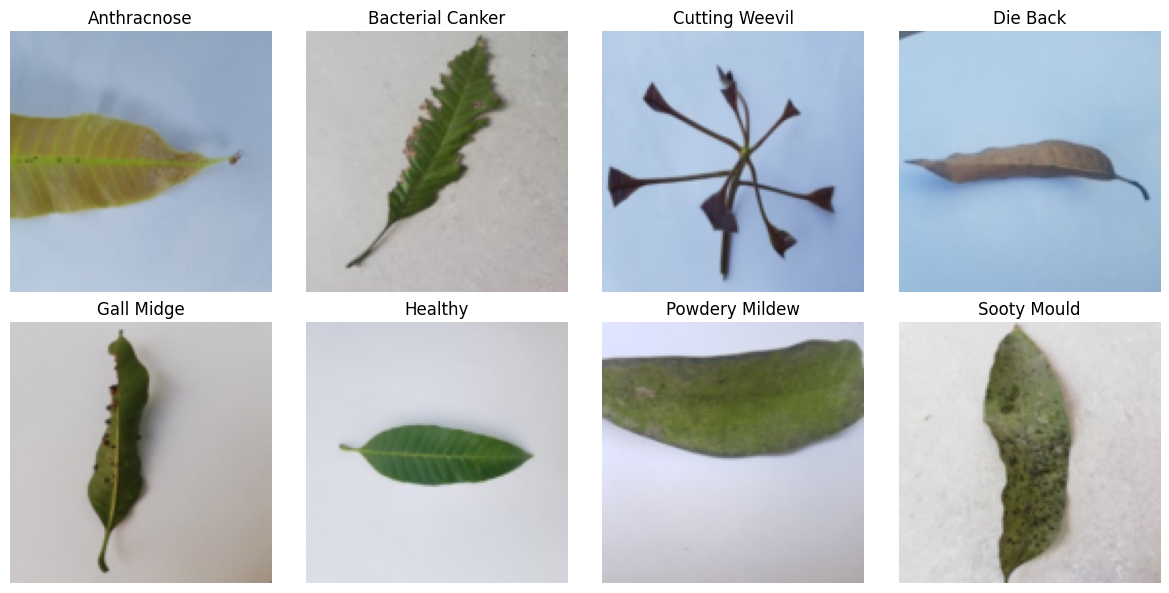

In [ ]:
plt.figure(figsize=(12,6))
for i in range(num_classes):
    first = [j for j, (_, l) in enumerate(full_val.samples) if l == i][0]
    img, label = full_val[first]
    plt.subplot(2, 4, i+1)
    plt.imshow(img.permute(1,2,0))     # [C,H,W] -> [H,W,C]
    plt.title(class_names[label])
    plt.axis("off")
plt.tight_layout()
plt.show()

## 4. Hyperparameters and DataLoaders

In [ ]:
batch_size = 32
learning_rate = 0.001
minimum_learning_rate = 1e-4
epochs = 25

train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(test_data,  batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)

## 5. Build the CNN from scratch

**A) Feature extractor** (4 convolution blocks). Each block is:
- **Conv2d** with 3x3 filters (padding=1 keeps the size the same)
- **ReLU** to add non-linearity
- **MaxPool2d(2)** to halve the height and width

**B) Classification head**: Flatten, then Linear layers, with **Dropout(0.5)** to reduce overfitting.

Shape flow for one image:
```
Input            3 x 128 x 128
Conv(32)+Pool   32 x  64 x  64
Conv(64)+Pool   64 x  32 x  32
Conv(128)+Pool 128 x  16 x  16
Conv(128)+Pool 128 x   8 x   8
Flatten        8192
Linear -> 256 -> Dropout -> Linear -> 8 class scores
```

In [ ]:
from torch.optim import Adam
from torch.optim.lr_scheduler import CosineAnnealingLR

class CNNModel(nn.Module):
    def __init__(self, num_classes=8):
        super(CNNModel, self).__init__()

        # Convolutional layers (feature extraction)
        self.conv_layers = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),     # 32x128x128
            nn.ReLU(),
            nn.MaxPool2d(2),                                # 32x64x64

            nn.Conv2d(32, 64, kernel_size=3, padding=1),    # 64x64x64
            nn.ReLU(),
            nn.MaxPool2d(2),                                # 64x32x32

            nn.Conv2d(64, 128, kernel_size=3, padding=1),   # 128x32x32
            nn.ReLU(),
            nn.MaxPool2d(2),                                # 128x16x16

            nn.Conv2d(128, 128, kernel_size=3, padding=1),  # 128x16x16
            nn.ReLU(),
            nn.MaxPool2d(2),                                # 128x8x8
        )

        # Fully connected layers (classification head)
        self.fc_layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128*8*8, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.conv_layers(x)
        x = self.fc_layers(x)
        return x

# 1. Get the model
model = CNNModel(num_classes=num_classes).to(device)
# 2. Optimizer
optimizer = Adam(model.parameters(), lr=learning_rate)
# 3. Learning rate scheduler
scheduler = CosineAnnealingLR(optimizer, T_max=epochs, eta_min=minimum_learning_rate)
# 4. Loss function
criterion = nn.CrossEntropyLoss()

print(model)
print(f"Total trainable parameters: {sum(p.numel() for p in model.parameters()):,}")

CNNModel(
  (conv_layers): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc_layers): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=8192, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=256, out_features=8, bias=True)
  )
)


## 6. Training and validation functions

In [ ]:
def train_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()        # backpropagation
        optimizer.step()       # update weights

        total_loss += loss.item()
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
    return total_loss / len(loader), correct / total


def validate_epoch(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0, 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item()
            _, preds = torch.max(outputs, 1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)
    return total_loss / len(loader), correct / total

## 7. Train the model

In [ ]:
train_losses, train_accuracies = [], []
val_losses, val_accuracies = [], []
best_val_acc = 0

for epoch in range(epochs):
    print("----------------------------------------------------")
    print(f"Epoch {epoch+1}/{epochs}, LR: {optimizer.param_groups[0]['lr']:.6g}")

    train_loss, train_acc = train_epoch(model, train_loader, optimizer, criterion, device)
    val_loss, val_acc = validate_epoch(model, val_loader, criterion, device)
    scheduler.step()

    train_losses.append(train_loss); train_accuracies.append(train_acc)
    val_losses.append(val_loss);     val_accuracies.append(val_acc)

    # keep the best model
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), "best_mango_cnn.pth")

    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
    print(f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

print(f"\nBest validation accuracy: {best_val_acc:.4f}")

----------------------------------------------------
Epoch 1/25, LR: 0.001
Train Loss: 1.7918 | Train Acc: 0.2541
Val Loss: 1.5256 | Val Acc: 0.3300
----------------------------------------------------
Epoch 2/25, LR: 0.000996452
Train Loss: 1.2955 | Train Acc: 0.4881
Val Loss: 1.0515 | Val Acc: 0.5938
----------------------------------------------------
Epoch 3/25, LR: 0.000985862
Train Loss: 0.8917 | Train Acc: 0.6672
Val Loss: 0.6043 | Val Acc: 0.7712
----------------------------------------------------
Epoch 4/25, LR: 0.000968399
Train Loss: 0.7240 | Train Acc: 0.7362
Val Loss: 0.4299 | Val Acc: 0.8488
----------------------------------------------------
Epoch 5/25, LR: 0.000944338
Train Loss: 0.5823 | Train Acc: 0.7819
Val Loss: 0.5355 | Val Acc: 0.8013
----------------------------------------------------
Epoch 6/25, LR: 0.000914058
Train Loss: 0.5478 | Train Acc: 0.7956
Val Loss: 0.3811 | Val Acc: 0.8588
----------------------------------------------------
Epoch 7/25, LR: 0.00087

# Result Analysis

## 8. Loss and accuracy curves

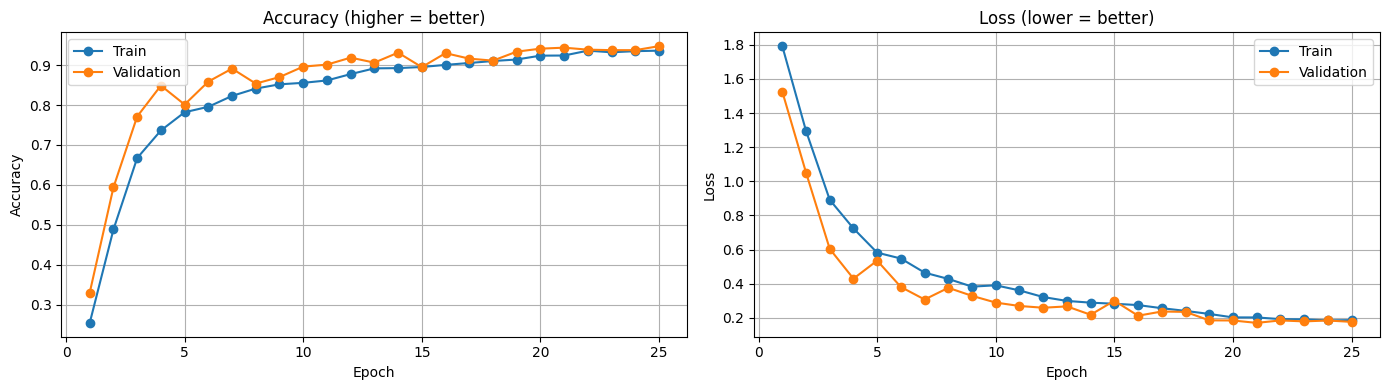

Final train acc: 0.9363
Final val acc  : 0.9475
Train - Val gap: -0.0112  -> no serious overfitting


In [ ]:
epochs_number = np.arange(1, epochs + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

ax1.plot(epochs_number, train_accuracies, "o-", label="Train")
ax1.plot(epochs_number, val_accuracies,   "o-", label="Validation")
ax1.set_title("Accuracy (higher = better)")
ax1.set_xlabel("Epoch"); ax1.set_ylabel("Accuracy"); ax1.legend(); ax1.grid(True)

ax2.plot(epochs_number, train_losses, "o-", label="Train")
ax2.plot(epochs_number, val_losses,   "o-", label="Validation")
ax2.set_title("Loss (lower = better)")
ax2.set_xlabel("Epoch"); ax2.set_ylabel("Loss"); ax2.legend(); ax2.grid(True)

plt.tight_layout()
plt.savefig("training_curves.png", dpi=150)
plt.show()

gap = train_accuracies[-1] - val_accuracies[-1]
print(f"Final train acc: {train_accuracies[-1]:.4f}")
print(f"Final val acc  : {val_accuracies[-1]:.4f}")
print(f"Train - Val gap: {gap:.4f}  ->", "possible overfitting" if gap > 0.05 else "no serious overfitting")

## 9. Confusion matrix and classification report

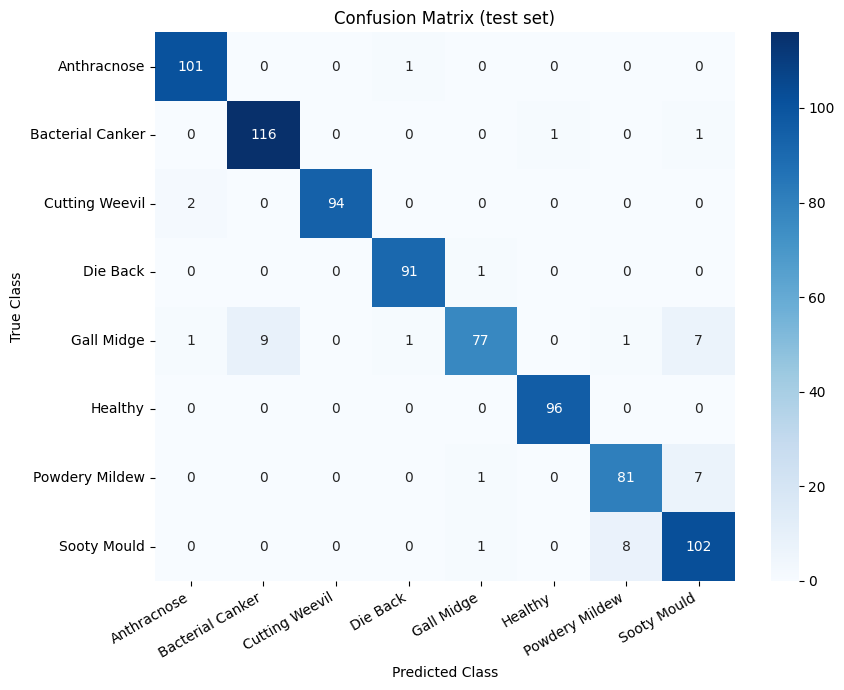

                  precision    recall  f1-score   support

     Anthracnose     0.9712    0.9902    0.9806       102
Bacterial Canker     0.9280    0.9831    0.9547       118
  Cutting Weevil     1.0000    0.9792    0.9895        96
        Die Back     0.9785    0.9891    0.9838        92
      Gall Midge     0.9625    0.8021    0.8750        96
         Healthy     0.9897    1.0000    0.9948        96
  Powdery Mildew     0.9000    0.9101    0.9050        89
     Sooty Mould     0.8718    0.9189    0.8947       111

        accuracy                         0.9475       800
       macro avg     0.9502    0.9466    0.9473       800
    weighted avg     0.9486    0.9475    0.9469       800

Total misclassified: 42 out of 800


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

# load the best saved model
model.load_state_dict(torch.load("best_mango_cnn.pth", map_location=device))
model.eval()

all_preds, all_labels, misclassified = [], [], []
with torch.no_grad():
    for images, labels in val_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        for img, t, p in zip(images, labels, preds):
            if t != p:
                misclassified.append((img.cpu(), t.item(), p.item()))

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(9,7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted Class"); plt.ylabel("True Class")
plt.title("Confusion Matrix (test set)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

print(classification_report(all_labels, all_preds, target_names=class_names, digits=4))
print(f"Total misclassified: {len(misclassified)} out of {len(all_labels)}")

## 10. Misclassified images

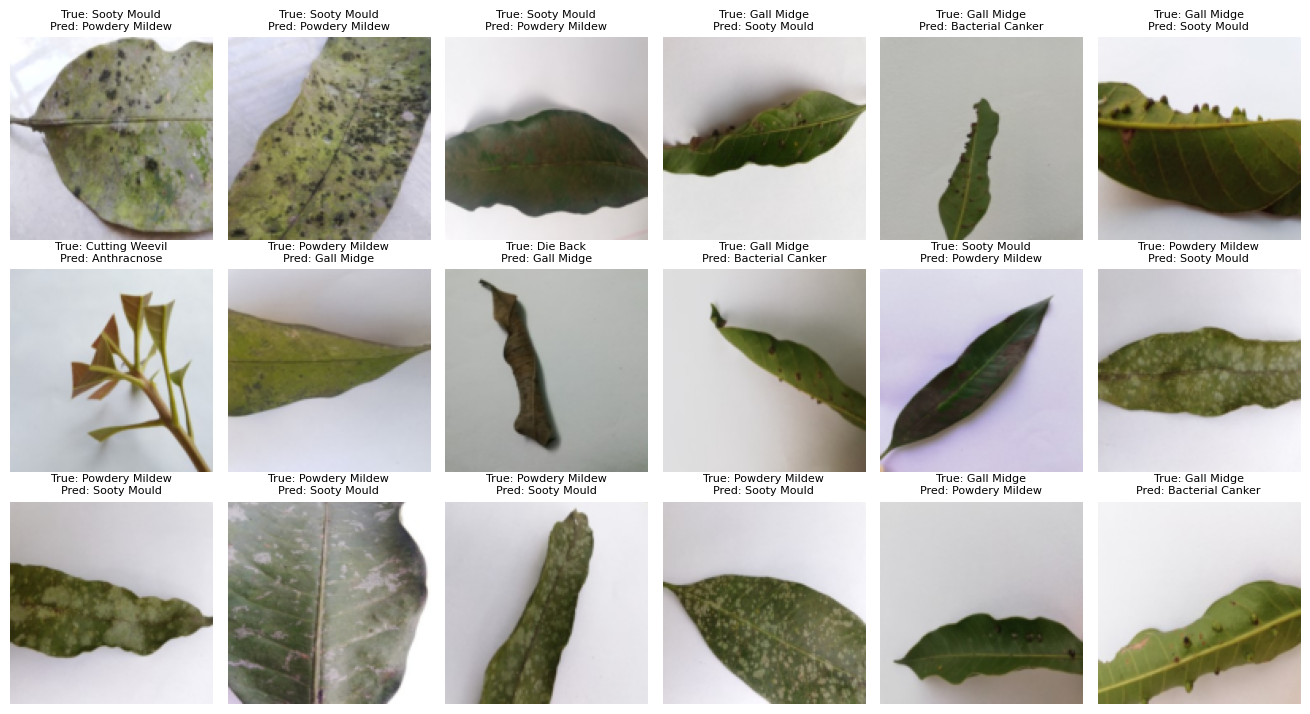

In [ ]:
num_rows, num_cols = 3, 6
num_to_show = min(num_rows*num_cols, len(misclassified))

fig, axes = plt.subplots(num_rows, num_cols, figsize=(num_cols*2.2, num_rows*2.4))
axes = axes.flatten()
for i in range(num_to_show):
    img, t, p = misclassified[i]
    axes[i].imshow(img.permute(1,2,0))
    axes[i].set_title(f"True: {class_names[t]}\nPred: {class_names[p]}", fontsize=8)
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

## 11. Predictions on random test images

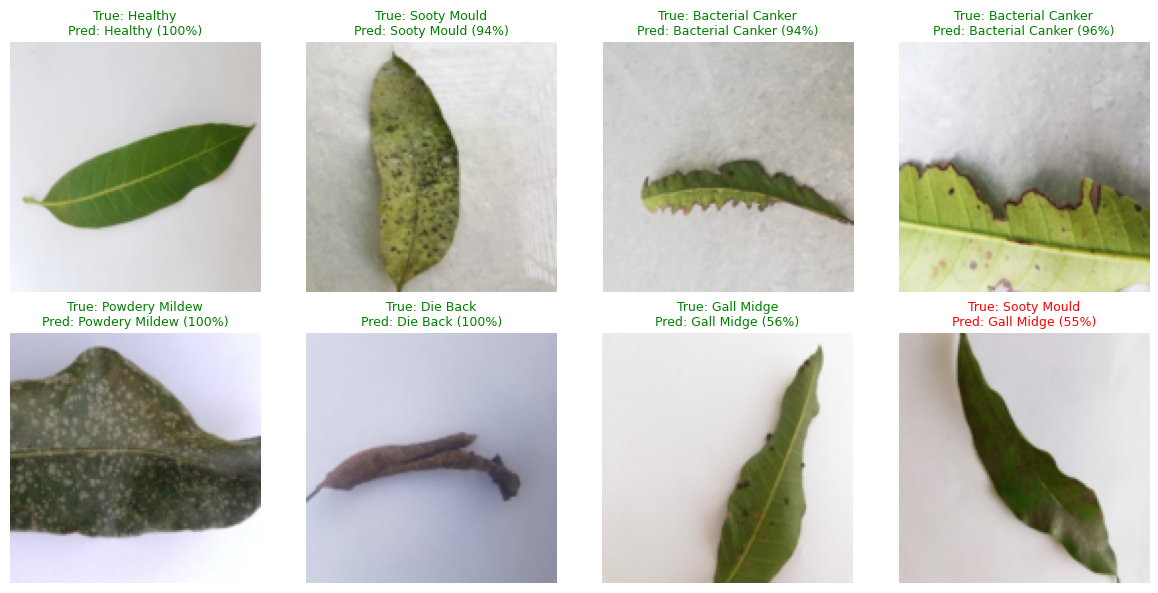

In [ ]:
plt.figure(figsize=(12,6))
for i in range(8):
    ix = np.random.randint(len(test_data))
    img, label = test_data[ix]
    with torch.no_grad():
        prob = F.softmax(model(img.unsqueeze(0).to(device)), dim=1)[0].cpu()
    pred = prob.argmax().item()
    plt.subplot(2, 4, i+1)
    plt.imshow(img.permute(1,2,0))
    color = "green" if pred == label else "red"
    plt.title(f"True: {class_names[label]}\nPred: {class_names[pred]} ({prob[pred]*100:.0f}%)", fontsize=9, color=color)
    plt.axis("off")
plt.tight_layout()
plt.show()

## 12. What the CNN learned: filters and feature maps
- **Filters** of the first conv layer: the 3x3 weight grids. They act like small edge and colour detectors.
- **Feature maps**: the output of a conv layer for one image. Bright areas show where a filter found its pattern.
- Early layers show clear edges of the leaf. The last conv layer is small (16x16) and more abstract.

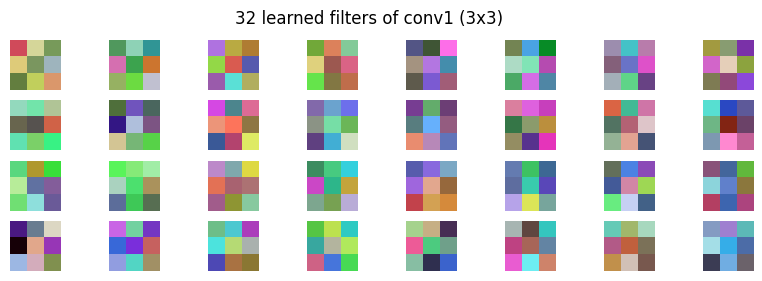

In [ ]:
# (1) First-layer filters
weights = model.conv_layers[0].weight.data.clone().cpu()     # [32, 3, 3, 3]
weights = (weights - weights.min()) / (weights.max() - weights.min() + 1e-8)
plt.figure(figsize=(10,3))
for i in range(32):
    plt.subplot(4, 8, i+1)
    plt.imshow(weights[i].permute(1,2,0))
    plt.axis("off")
plt.suptitle("32 learned filters of conv1 (3x3)")
plt.show()

Early feature maps: (32, 128, 128)
Last feature maps : (128, 16, 16)


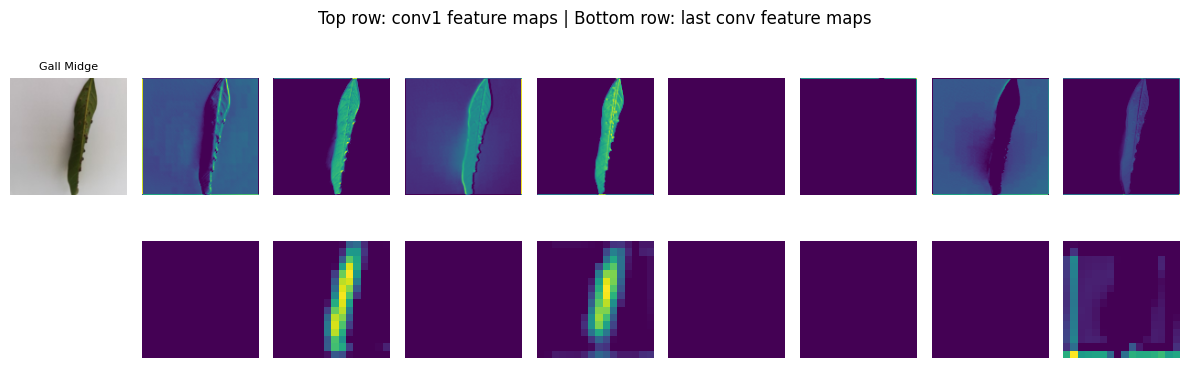

In [ ]:
# (2) Feature maps: first conv layer vs last conv layer
img, label = test_data[0]
x = img.unsqueeze(0).to(device)

with torch.no_grad():
    early = F.relu(model.conv_layers[0](x)).cpu()[0]     # after conv1 -> 32 x 128 x 128
    feats = x
    for layer in model.conv_layers[:-1]:                  # run up to the last ReLU
        feats = layer(feats)
    last = feats.cpu()[0]                                 # last conv -> 128 x 16 x 16

print("Early feature maps:", tuple(early.shape))
print("Last feature maps :", tuple(last.shape))

plt.figure(figsize=(12,4))
plt.subplot(2, 9, 1); plt.imshow(img.permute(1,2,0)); plt.title(class_names[label], fontsize=8); plt.axis("off")
for i in range(8):
    plt.subplot(2, 9, i+2); plt.imshow(early[i], cmap="viridis"); plt.axis("off")
for i in range(8):
    plt.subplot(2, 9, i+11); plt.imshow(last[i], cmap="viridis"); plt.axis("off")
plt.suptitle("Top row: conv1 feature maps | Bottom row: last conv feature maps")
plt.tight_layout()
plt.show()

## 13. Conclusion

- **Dataset:** MangoLeafBD from Mendeley Data. It has 4,000 images in 8 balanced classes (7 diseases plus Healthy). I split it 80/20, so 3,200 images were used for training and 800 for testing.
- **Model:** a basic CNN built from scratch with 4 conv blocks (Conv + ReLU + MaxPool) and a fully connected head with dropout. It has 2,340,296 trainable parameters.
- **Best test accuracy:** 94.75% at epoch 25. The model got 758 of the 800 test images right and misclassified 42. The lowest validation loss was 0.1708 at epoch 21.
- **Overfitting:** the train and validation curves stayed close for the whole run. Final train accuracy was 93.63% and test accuracy was 94.75%, so there was no overfitting. Test accuracy came out slightly higher because augmentation and dropout make training harder, while testing uses clean images with dropout turned off.
- **Most confused classes:** Gall Midge was the weakest class (recall 80%). The model mistook 9 Gall Midge leaves for Bacterial Canker and 7 for Sooty Mould. Powdery Mildew and Sooty Mould were also mixed up with each other (7 and 8 images). These diseases all leave dark or blotchy marks on the leaf, so they can look alike, especially after resizing to 128 x 128.
- **Easiest classes:** Healthy had 100% recall, and Cutting Weevil, Die Back and Anthracnose all had F1 scores above 0.98. These classes have clearer and more distinct visual signs.
- **Possible improvements:** training for more epochs, using a larger image size so small spots stay visible, adding batch normalization, or trying transfer learning with a pretrained model such as ResNet.